## Team
- Rey Sioson
- Cohen Kang

## Problem Statement
This project will predict whether a bank customer **leaves or stays**, using customer and account information. Identifying customers who may leave could help a bank decide where to focus retention efforts.


## Dataset
We plan to use Kaggle's public **Churn Modelling** dataset.

| Property | Details |
|---|---|
| Size | 10,000 rows × 14 columns |
| Predictors | 10 substantive customer/account predictors |
| Identifier-like columns | `RowNumber`, `CustomerId`, `Surname` |
| Target | `Exited` (1 = left, 0 = stayed) |
| Churners | 2,037 (20.37%) |
| Non-churners | 7,963 (79.63%) |
| Class ratio | ≈ 3.9 non-churners per churner |
| Missing values | Reported to have none |

In [38]:
# imports
import pandas as pd
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc, roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV

# Load the Churn_Modelling.xls dataset
df = pd.read_csv("Churn_Modelling.xls")

In [39]:
# define features and target variable
X = df.drop(columns=["Exited", "RowNumber", "CustomerId", "Surname"])  # Features (all columns except: Exited, RowNumber, CustomerId, and Surname, which are not relevant for prediction)
y = df["Exited"]  # Target variable ('Exited')
# one-hot encode categorical columns
X = pd.get_dummies(X, columns=["Geography", "Gender"], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split( #split the dataset with test_size=0.2
    X,
    y,
    test_size=0.20,
    train_size=0.80,
    stratify=y,
    random_state=42,
)

# scale: fit on train only, then apply to test
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## Planned Methods

| Model | Rationale |
|---|---|
| **Baseline: majority-class classifier** | Predicting "stayed" for every customer gives a simple reference point and shows why accuracy alone can be misleading here. |
| **Logistic regression** | A straightforward, interpretable model that provides a useful comparison for binary classification. |
| **Decision tree** | Can capture nonlinear patterns and interactions, and its decision rules are relatively easy to inspect. |
| **Random forest** | Combines many trees, which can improve predictive performance an

In [40]:
# baseline majority class model using DummyClassifier
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
y_pred = baseline.predict(X_test)
print("Baseline accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Baseline accuracy: 0.7965
[[1593    0]
 [ 407    0]]
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1593
           1       0.00      0.00      0.00       407

    accuracy                           0.80      2000
   macro avg       0.40      0.50      0.44      2000
weighted avg       0.63      0.80      0.71      2000



In [41]:
# logistic regression model

log_reg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
log_reg.fit(X_train_s, y_train)

y_pred = log_reg.predict(X_test_s)
y_prob = log_reg.predict_proba(X_test_s)[:, 1]   # churn probabilities, for ROC

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

fpr, tpr, _ = roc_curve(y_test, y_prob)
print("ROC AUC:", auc(fpr, tpr))


[[1142  451]
 [ 122  285]]
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1593
           1       0.39      0.70      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000

ROC AUC: 0.7771376923919298


In [42]:
# decision tree model

dt = DecisionTreeClassifier(class_weight="balanced", random_state=42)
dt.fit(X_train_s, y_train)
print("Train Accuracy:", accuracy_score(y_train, dt.predict(X_train_s)))
pred = dt.predict(X_test_s)
accuracy = accuracy_score(y_test, pred)
print("Base Decision Tree Test Accuracy:", accuracy)
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, dt.predict_proba(X_test_s)[:, 1]))


Train Accuracy: 1.0
Base Decision Tree Test Accuracy: 0.7715
[[1356  237]
 [ 220  187]]
              precision    recall  f1-score   support

           0       0.86      0.85      0.86      1593
           1       0.44      0.46      0.45       407

    accuracy                           0.77      2000
   macro avg       0.65      0.66      0.65      2000
weighted avg       0.78      0.77      0.77      2000

ROC AUC: 0.6553417824604265


In [43]:
# explore how max-depth parameter affects decision tree performance
depth_search = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=42),
    {"max_depth": list(range(1, 21))},
    scoring="f1", cv=5,
)
depth_search.fit(X_train_s, y_train)
print("Best max_depth:", depth_search.best_params_["max_depth"])

dt_depth = depth_search.best_estimator_
print("Train Accuracy:", accuracy_score(y_train, dt_depth.predict(X_train_s)))
pred = dt_depth.predict(X_test_s)
print("Test Accuracy:", accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, dt_depth.predict_proba(X_test_s)[:, 1]))


Best max_depth: 6
Train Accuracy: 0.775875
Test Accuracy: 0.7585
[[1204  389]
 [  94  313]]
              precision    recall  f1-score   support

           0       0.93      0.76      0.83      1593
           1       0.45      0.77      0.56       407

    accuracy                           0.76      2000
   macro avg       0.69      0.76      0.70      2000
weighted avg       0.83      0.76      0.78      2000

ROC AUC: 0.8331783247037485


In [44]:
# post-pruning: grow the full tree, then cut back branches using ccp_alpha
path = DecisionTreeClassifier(class_weight="balanced", random_state=42).cost_complexity_pruning_path(X_train_s, y_train)
ccp_alphas = path.ccp_alphas[:-1]   # drop last alpha because it prunes to just the root
alpha_grid = np.unique(np.quantile(ccp_alphas, np.linspace(0, 1, 40)))  # narrow down all alpha values to ~40 evenly spread values

# find best alpha value using GridSearchCV with 5-fold cross-validation and f1 score as the metric
alpha_search = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=42),
    {"ccp_alpha": alpha_grid},
    scoring="f1", cv=5,
)
alpha_search.fit(X_train_s, y_train)
print("Best ccp_alpha:", alpha_search.best_params_["ccp_alpha"])

dt_post = alpha_search.best_estimator_
print("Train Accuracy:", accuracy_score(y_train, dt_post.predict(X_train_s)))
pred = dt_post.predict(X_test_s)
print("Test Accuracy:", accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, dt_post.predict_proba(X_test_s)[:, 1]))


Best ccp_alpha: 0.0010622255798546272
Train Accuracy: 0.771375
Test Accuracy: 0.761
[[1205  388]
 [  90  317]]
              precision    recall  f1-score   support

           0       0.93      0.76      0.83      1593
           1       0.45      0.78      0.57       407

    accuracy                           0.76      2000
   macro avg       0.69      0.77      0.70      2000
weighted avg       0.83      0.76      0.78      2000

ROC AUC: 0.852423301575844


In [45]:
# random forest model

# base random forest (default settings) to compare against the single decision tree
# n_jobs=-1 use all available CPU cores for parallel processing
rf = RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1)
rf.fit(X_train_s, y_train)
print("Base RF Train Accuracy:", accuracy_score(y_train, rf.predict(X_train_s)))
print("Base RF Test Accuracy:", accuracy_score(y_test, rf.predict(X_test_s)))
print(confusion_matrix(y_test, rf.predict(X_test_s)))
print(classification_report(y_test, rf.predict(X_test_s)))
print("Base RF ROC AUC:", roc_auc_score(y_test, rf.predict_proba(X_test_s)[:, 1]))

# tune the forest with GridSearchCV (5-fold CV, f1 score), same approach as the decision tree
rf_search = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
    {
        "n_estimators": [100, 300],          # number of trees
        "max_depth": [6, 8, 10, None],       # limit tree depth to reduce overfitting
        "min_samples_leaf": [1, 5],          # minimum samples required in a leaf
    },
    scoring="f1", cv=5,
)
rf_search.fit(X_train_s, y_train)
print("Best params:", rf_search.best_params_)

rf_best = rf_search.best_estimator_
print("Train Accuracy:", accuracy_score(y_train, rf_best.predict(X_train_s)))
pred = rf_best.predict(X_test_s)
y_prob = rf_best.predict_proba(X_test_s)[:, 1]   # churn probabilities, for ROC
print("Test Accuracy:", accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))


Base RF Train Accuracy: 1.0
Base RF Test Accuracy: 0.86
[[1542   51]
 [ 229  178]]
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.78      0.44      0.56       407

    accuracy                           0.86      2000
   macro avg       0.82      0.70      0.74      2000
weighted avg       0.85      0.86      0.84      2000

Base RF ROC AUC: 0.8508354271066135
Best params: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}
Train Accuracy: 0.925625
Test Accuracy: 0.8445
[[1430  163]
 [ 148  259]]
              precision    recall  f1-score   support

           0       0.91      0.90      0.90      1593
           1       0.61      0.64      0.62       407

    accuracy                           0.84      2000
   macro avg       0.76      0.77      0.76      2000
weighted avg       0.85      0.84      0.85      2000

ROC AUC: 0.8637697790240162


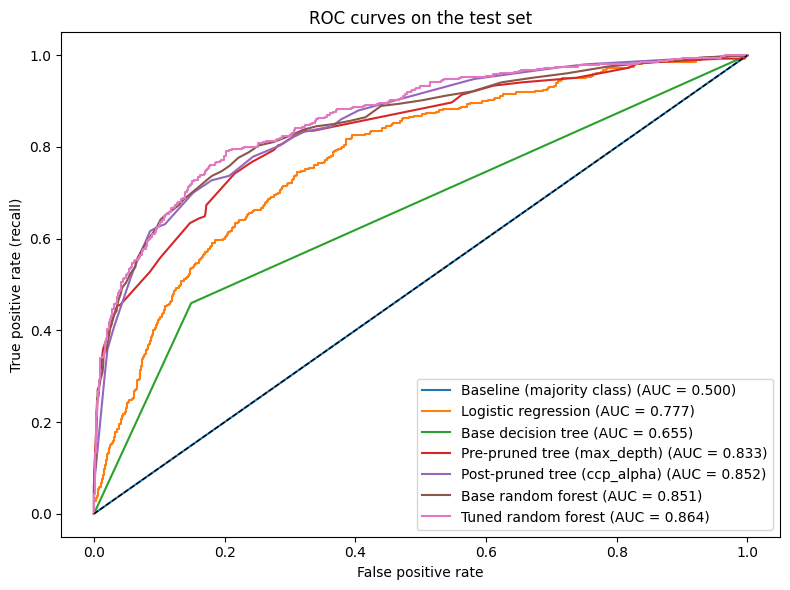

In [46]:
# ROC curves for every model on the test set
models = {
    "Baseline (majority class)": (baseline, X_test),
    "Logistic regression": (log_reg, X_test_s),
    "Base decision tree": (dt, X_test_s),
    "Pre-pruned tree (max_depth)": (dt_depth, X_test_s),
    "Post-pruned tree (ccp_alpha)": (dt_post, X_test_s),
    "Base random forest": (rf, X_test_s),
    "Tuned random forest": (rf_best, X_test_s),
}

plt.figure(figsize=(8, 6))
for name, (model, X_eval) in models.items():
    probs = model.predict_proba(X_eval)[:, 1]   # churn probabilities
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "k--", linewidth=1)   # random-guess reference line
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Decision Tree vs. Random Forest Comparison

| Metric | Base Tree | Pre-pruned Tree (`max_depth=7`) | Post-pruned Tree (`ccp_alpha≈0.0011`) | Base Random Forest | Tuned Random Forest (`n_estimators=300`, `min_samples_leaf=5`) |
|---|---|---|---|---|---|
| Train accuracy | 1.000 | 0.806 | 0.765 | 1.000 | 0.928 |
| Test accuracy | 0.781 | 0.782 | 0.747 | **0.869** | 0.853 |
| Train − test gap | 0.219 | 0.024 | **0.019** | 0.132 | 0.075 |
| Precision (churn = 1) | 0.45 | 0.47 | 0.42 | **0.79** | 0.62 |
| Recall (churn = 1) | 0.50 | 0.73 | **0.78** | 0.46 | 0.65 |
| F1 (churn = 1) | 0.47 | 0.57 | 0.55 | 0.58 | **0.63** |
| Precision (stayed = 0) | 0.87 | 0.92 | **0.93** | 0.88 | 0.91 |
| Recall (stayed = 0) | 0.85 | 0.79 | 0.74 | **0.97** | 0.90 |
| F1 (stayed = 0) | 0.86 | 0.85 | 0.82 | **0.92** | 0.91 |
| Macro avg F1 | 0.67 | 0.71 | 0.69 | 0.75 | **0.77** |
| ROC AUC | 0.676 | 0.833 | 0.848 | 0.856 | **0.869** |

- The **base tree** overfits: it scores 100% on training data but only 78.1% on the test set, and it finds only half of the churners.
- **Pre-pruning** with `max_depth=7` keeps the same test accuracy while shrinking the train–test gap from 0.219 to 0.024, and it has the best churn F1 of the single trees (0.57).
- **Post-pruning** with `ccp_alpha` generalizes about as well (gap 0.019) and finds the most churners of any model (recall 0.78), but it has the lowest test accuracy and churn precision.
- The **base random forest** has the highest test accuracy (0.869) and churn precision (0.79), even though each of its trees is fully grown, because averaging many trees reduces overfitting. However, it finds only 46% of churners, which shows why accuracy alone is misleading here.
- The **tuned random forest** (selected by 5-fold CV on F1, with no depth limit and `min_samples_leaf=5`) gives the best balance: the highest churn F1 (0.63), macro F1 (0.77), and ROC AUC (0.869). It trades some recall relative to the pruned trees (0.65 vs. 0.73–0.78) for much higher precision (0.62 vs. 0.42–0.47).
- Pruning and tuning improve churn recall and F1 even when test accuracy stays flat or drops slightly, so accuracy alone would hide most of the improvement.

## Evaluation Plan
- **Data split:** Use a **stratified train/test split** to preserve the class ratio, and keep the test set out of model selection.
- **Metrics:** Compare recall, precision, F1, ROC, accuracy, and the confusion matrix.
  - **Recall** – how many actual churners are found.
  - **Precision** – how often a churn prediction is correct.
  - **F1** – balances precision and recall.
- **Accuracy caveat:** Because churners are only 20.37% of the data, we will **not** rely on accuracy alone.
- **Tuning:** If tuning the decision threshold or using class weights, do so with cross-validation on the training data.

## Risks

| Risk | Mitigation |
|---|---|
| The dataset may be too small or unrepresentative to support conclusions about real-world bank customers. | Present findings as a comparison **on this dataset only**; if reliable generalization is not possible, report that limitation rather than overstate results. |
| Identifier-like fields could introduce misleading patterns if included. | Inspect and exclude non-informative identifiers (`RowNumber`, `CustomerId`, `Surname`). |
| Class imbalance may lead a model to miss churners while still achieving high accura